<a href="https://colab.research.google.com/github/eryk-mar/CS4207_Cafepos/blob/master/GP%20Multiple%20runs%20on%20an%20arbitrary%20Symbolic%20Regression%20Problem.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

# GP Multiple runs on an Salustowicz 1D symbolic Regression Problem.

Install DEAP.

In [39]:
!pip install deap
!pip install python-docx

Import our tools.

In [40]:
import operator
import math
import random
import os
import urllib.request

import numpy

from deap import algorithms
from deap import base
from deap import creator
from deap import tools
from deap import gp

from docx import Document

import matplotlib.pyplot as plt

numpy.seterr(all='ignore')




{'divide': 'ignore', 'over': 'ignore', 'under': 'ignore', 'invalid': 'ignore'}

Download the datasets for training and validation



In [41]:
from typing import Text
DATA_DIR = "."
TRAIN_FILE = os.path.join(DATA_DIR, "salustowicz_input_file.docx")
TEST_FILE = os.path.join(DATA_DIR, "salustowicz_test_dataset.docx")
BASE_URL = "https://hygprogramming.wordpress.com/wp-content/uploads/2014/04/"
missing = []

for path in (TRAIN_FILE, TEST_FILE):
  if os.path.exists(path):
    continue
  try:
    urllib.request.urlretrieve(BASE_URL + os.path.basename(path), path)
  except:
    missing.append(path)

Reading the docx files

In [42]:
def read_gp_docx(path):
    settings, rows = {}, []
    for p in Document(path).paragraphs:
        for line in p.text.splitlines():
            line = line.strip()
            if not line or line.startswith('#'):
                continue
            if '=' in line:
                key, val = line.split('=', 1)
                settings[key.strip()] = val.strip()
                continue
            try:
                rows.append([float(v) for v in line.split()])
            except ValueError:
                pass
    return settings, rows

cfg, train = read_gp_docx(TRAIN_FILE)
_, test = read_gp_docx(TEST_FILE)

nvar, ncases = map(int, test[0])
test = test[1:]

assert len(train) == int(cfg['NFITCASES']), f"expected {cfg['NFITCASES']} training rows, got {len(train)}"
assert len(test) == ncases, f"expected {ncases} test rows, got {len(test)}"

print("Training rows:", len(train), " x from", min(r[0] for r in train), "to", max(r[0] for r in train))
print("Test rows:    ", len(test),  " x from", min(r[0] for r in test),  "to", max(r[0] for r in test))
print("Function set in file:", cfg['BINARY_FUN'], "|", cfg['UNARY_FUN'])

Training rows: 100  x from 0.05 to 9.950000000000001
Test rows:     221  x from -0.5 to 10.5
Function set in file: add,sub,mult,sdiv | square,sin,cos,exp


Plotting the Salustowicz 1D problem

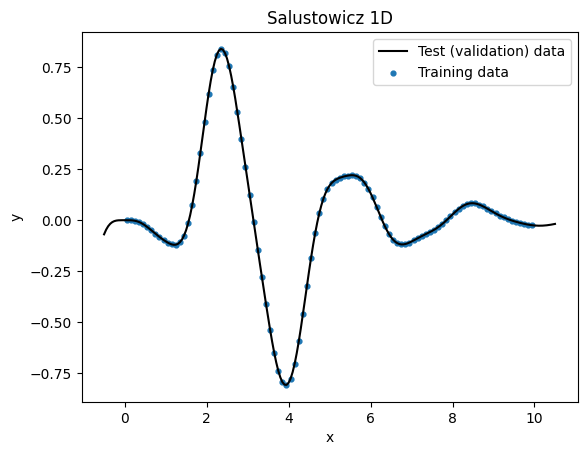

In [43]:
plt.plot([r[0] for r in test], [r[1] for r in test], 'k-', label='Test (validation) data')
plt.scatter([r[0] for r in train], [r[1] for r in train], s=12, label='Training data')
plt.xlabel('x'); plt.ylabel('y'); plt.title('Salustowicz 1D'); plt.legend()
plt.show()

Set our Genetic Programming parameters, one of which is now the number of runs.

In [44]:
# Genetic Programming constants (as specified from the input file):
POPULATION_SIZE = int(cfg['M'])              # 300
MAX_GENERATIONS = int(cfg['G'])              # 50
P_CROSSOVER     = float(cfg['CROSS_RATE'])   # 0.4
P_MUTATION      = float(cfg['MUT_RATE'])     # 0.5  (remaining 0.1 = reproduction)
NVAR            = int(cfg['NVAR'])           # 1 input variable
LOW, HIGH       = float(cfg['MINRAND']), float(cfg['MAXRAND'])   # random constants in [-200, 200]

# Our own choices:
N_RUNS = 30
HALL_OF_FAME_SIZE = 10
TOURNAMENT_SIZE = 3
MAX_ERROR = 10.0       # worst possible fitness (error cap)

Set the random seed.

In [45]:
RANDOM_SEED = 412
random.seed(RANDOM_SEED)

GP-Specific constants.

In [46]:
# GP-specific constants (from the input file):
MIN_TREE_HEIGHT   = int(cfg['DEPTH_MIN'])    # 2
MAX_TREE_HEIGHT   = int(cfg['DEPTH_MAX'])    # 4
LIMIT_TREE_HEIGHT = int(cfg['DEPTH_LIM'])    # 8
MUT_MIN_TREE_HEIGHT = 0
MUT_MAX_TREE_HEIGHT = 2

Define our fitness function.

In [47]:
def mse(func, data):
    try:
        err = float(sum((func(*row[:-1]) - row[-1]) ** 2 for row in data) / len(data))
    except (OverflowError, ValueError, ZeroDivisionError, TypeError):
        return MAX_ERROR
    if not math.isfinite(err) or err > MAX_ERROR:
        return MAX_ERROR
    return err

def evalSymbReg(individual):
    func = toolbox.compile(expr=individual)
    return mse(func, train),

Define a protected division function.

In [48]:
def protectedDiv(left, right):
    try:
        if right == 0:          # also catches numpy zeros, which don't raise ZeroDivisionError
            return 1
        return left / right
    except ZeroDivisionError:
        return 1

def psin(n):
    try:
        return numpy.sin(n)
    except Exception:
        return numpy.nan

def pcos(n):
    try:
        return numpy.cos(n)
    except Exception:
        return numpy.nan

def pow2(n):
    return operator.pow(n, 2)

def pexp(n):
    return numpy.exp(n)

Add our functions and terminals.

In [49]:
pset = gp.PrimitiveSet("MAIN", NVAR) # number of inputs
pset.addPrimitive(operator.add, 2)
pset.addPrimitive(operator.sub, 2)
pset.addPrimitive(operator.mul, 2)
pset.addPrimitive(protectedDiv, 2)
pset.addPrimitive(pow2, 1)
pset.addPrimitive(psin, 1)
pset.addPrimitive(pcos, 1)
pset.addPrimitive(pexp, 1)
pset.addEphemeralConstant("rand200", lambda: random.uniform(LOW, HIGH))
pset.renameArguments(ARG0='z')


/usr/local/lib/python3.13/dist-packages/deap/gp.py:257: RuntimeWarning: Ephemeral rand200 function cannot be pickled because its generating function is a lambda function. Use functools.partial instead.
  warnings.warn("Ephemeral {name} function cannot be "


Create our toolbox.

In [50]:
if not hasattr(creator, "FitnessMin"):
    creator.create("FitnessMin", base.Fitness, weights=(-1.0,))
if not hasattr(creator, "Individual"):
    creator.create("Individual", gp.PrimitiveTree, fitness=creator.FitnessMin)

toolbox = base.Toolbox()
toolbox.register("expr", gp.genHalfAndHalf, pset=pset, min_=MIN_TREE_HEIGHT, max_=MAX_TREE_HEIGHT)
toolbox.register("individual", tools.initIterate, creator.Individual, toolbox.expr)
toolbox.register("population", tools.initRepeat, list, toolbox.individual)
toolbox.register("compile", gp.compile, pset=pset)

toolbox.register("evaluate", evalSymbReg)
toolbox.register("select", tools.selTournament, tournsize=TOURNAMENT_SIZE)

toolbox.register("mate", gp.cxOnePoint)
toolbox.register("expr_mut", gp.genGrow, min_=MUT_MIN_TREE_HEIGHT, max_=MUT_MAX_TREE_HEIGHT)
toolbox.register("mutate", gp.mutUniform, expr=toolbox.expr_mut, pset=pset)

toolbox.decorate("mate", gp.staticLimit(key=operator.attrgetter("height"), max_value=LIMIT_TREE_HEIGHT))
toolbox.decorate("mutate", gp.staticLimit(key=operator.attrgetter("height"), max_value=LIMIT_TREE_HEIGHT))

Elitism

In [51]:
def eaSimpleWithElitism(population, toolbox, cxpb, mutpb, ngen, stats=None,
                        halloffame=None, verbose=__debug__):
    """eaSimple with elitism: the hall-of-fame individuals are copied straight into
    the next generation, untouched by selection, crossover and mutation."""
    logbook = tools.Logbook()
    logbook.header = ['gen', 'nevals'] + (stats.fields if stats else [])

    invalid_ind = [ind for ind in population if not ind.fitness.valid]
    for ind, fit in zip(invalid_ind, toolbox.map(toolbox.evaluate, invalid_ind)):
        ind.fitness.values = fit

    if halloffame is None:
        raise ValueError("halloffame parameter must not be empty!")
    halloffame.update(population)
    hof_size = len(halloffame.items) if halloffame.items else 0

    record = stats.compile(population) if stats else {}
    logbook.record(gen=0, nevals=len(invalid_ind), **record)
    if verbose:
        print(logbook.stream)

    for gen in range(1, ngen + 1):
        offspring = toolbox.select(population, len(population) - hof_size)
        offspring = algorithms.varOr(offspring, toolbox, len(offspring), cxpb, mutpb)

        invalid_ind = [ind for ind in offspring if not ind.fitness.valid]
        for ind, fit in zip(invalid_ind, toolbox.map(toolbox.evaluate, invalid_ind)):
            ind.fitness.values = fit

        offspring.extend(halloffame.items)      # add the best back
        halloffame.update(offspring)
        population[:] = offspring

        record = stats.compile(population) if stats else {}
        logbook.record(gen=gen, nevals=len(invalid_ind), **record)
        if verbose:
            print(logbook.stream)

    return population, logbook

Create our statistics. These are a bit more complex than the GA ones because we want to keep track of fitness and size for all runs.

In [52]:
maxListFitness = []
avgListFitness = []
minListFitness = []
stdListFitness = []

maxListSize = []
avgListSize = []
minListSize = []
stdListSize = []

results  = []
best_overall = None

Now the magic happens and we run **N_RUNS** times. Always start with a small number of runs and generations to make sure that everything is working properly before you commit to a larger number. That way, if something goes horribly wrong, Python won't replicate it 30 times before giving you back control!

In [53]:
for r in range(0, N_RUNS):
    population = toolbox.population(n=POPULATION_SIZE)
    # define the hall-of-fame object:
    hof = tools.HallOfFame(HALL_OF_FAME_SIZE)

    # Create our statistics
    stats_fit = tools.Statistics(lambda ind: ind.fitness.values[0])
    stats_size = tools.Statistics(len)
    mstats = tools.MultiStatistics(fitness=stats_fit, size=stats_size)
    mstats.register("avg", numpy.mean)
    mstats.register("std", numpy.std)
    mstats.register("min", numpy.min)
    mstats.register("max", numpy.max)

    # It's usually a good idea to turn off verbose when conducting multiple runs
    population, logbook = eaSimpleWithElitism(population, toolbox,
                                              cxpb=P_CROSSOVER, mutpb=P_MUTATION,
                                              ngen=MAX_GENERATIONS, stats=mstats,
                                              halloffame=hof, verbose=False)

    meanFitnessValues, stdFitnessValues, minFitnessValues, maxFitnessValues = logbook.chapters['fitness'].select("avg", "std", "min", "max")
    meanSizeValues, stdSizeValues, minSizeValues, maxSizeValues = logbook.chapters['size'].select("avg", "std", "min", "max")

    # Save statistics for this run:
    avgListFitness.append(meanFitnessValues)
    stdListFitness.append(stdFitnessValues)
    minListFitness.append(minFitnessValues)
    maxListFitness.append(maxFitnessValues)

    avgListSize.append(meanSizeValues)
    stdListSize.append(stdSizeValues)
    minListSize.append(minSizeValues)
    maxListSize.append(maxSizeValues)

    # best of this run, scored on the unseen test data:
    best = hof.items[0]
    train_err = best.fitness.values[0]
    test_err = mse(toolbox.compile(expr=best), test)
    results.append((r, train_err, test_err, len(best), best.height, str(best)))

    # best individual so far over all runs:
    if best_overall is None or train_err < best_overall.fitness.values[0]:
        best_overall = toolbox.clone(best)

    print(f"Run {r:2d}: train MSE {train_err:.5f}   test MSE {test_err:.5f}   length {len(best):3d}   height {best.height}")

Run  0: train MSE 0.01709   test MSE 0.11560   length  24   height 8
Run  1: train MSE 0.01715   test MSE 0.01617   length  22   height 7
Run  2: train MSE 0.01897   test MSE 0.01913   length  20   height 5
Run  3: train MSE 0.02733   test MSE 0.02479   length  20   height 8
Run  4: train MSE 0.01248   test MSE 10.00000   length  52   height 8
Run  5: train MSE 0.05358   test MSE 0.04853   length  28   height 8
Run  6: train MSE 0.03198   test MSE 10.00000   length  21   height 6
Run  7: train MSE 0.04516   test MSE 0.04094   length  16   height 6
Run  8: train MSE 0.03141   test MSE 0.05358   length  44   height 8
Run  9: train MSE 0.01817   test MSE 0.02299   length  19   height 8
Run 10: train MSE 0.07762   test MSE 0.07032   length  27   height 8
Run 11: train MSE 0.01467   test MSE 0.02110   length  49   height 7
Run 12: train MSE 0.01668   test MSE 0.01515   length  20   height 7
Run 13: train MSE 0.02913   test MSE 0.02672   length  21   height 7
Run 14: train MSE 0.01818   test

Summary of all runs

In [58]:
best_func = toolbox.compile(expr=best_overall)

print("-- Best Individual = ", best_overall)
print("-- length={}, height={}".format(len(best_overall), best_overall.height))
print("-- Training MSE = ", best_overall.fitness.values[0])
print("-- Test MSE = ", mse(best_func, test))

-- Best Individual =  protectedDiv(psin(z), add(protectedDiv(protectedDiv(protectedDiv(154.52378105026264, protectedDiv(z, z)), protectedDiv(z, z)), pexp(pow2(sub(pcos(z), 1.7283669886024313)))), add(protectedDiv(protectedDiv(sub(sub(25.199888525958215, z), pexp(z)), sub(-144.79325264805559, pcos(psin(-59.83767674763163)))), z), pcos(protectedDiv(z, z)))))
-- length=39, height=8
-- Training MSE =  0.011586638247767842
-- Test MSE =  0.010521677560322028


Graph average across all the runs with standard deviation and logscale

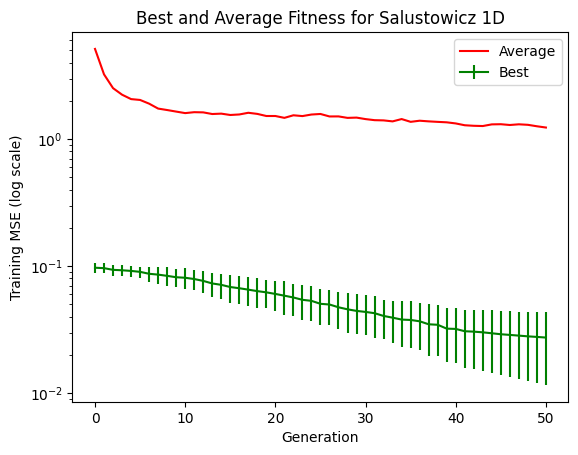

In [60]:
x = numpy.arange(0, MAX_GENERATIONS + 1)
avgArray = numpy.array(avgListFitness)
minArray = numpy.array(minListFitness)
plt.xlabel('Generation')
plt.ylabel('Training MSE (log scale)')
plt.title('Best and Average Fitness for Salustowicz 1D')
plt.errorbar(x, minArray.mean(0), yerr=minArray.std(0), label="Best", color="Green")
plt.plot(x, avgArray.mean(0), label="Average", color="Red")
plt.yscale('log')
plt.legend()
plt.show()

Graph for size

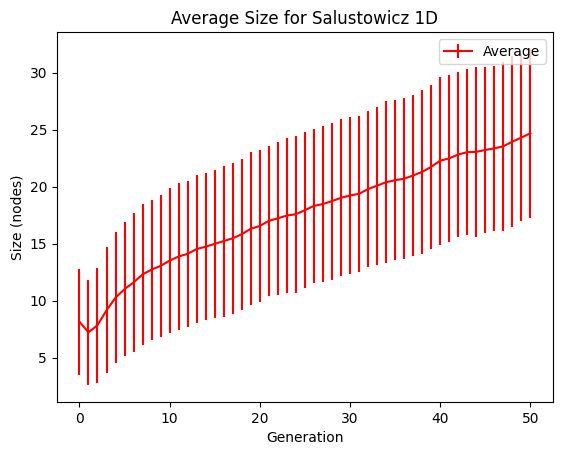

In [61]:
avgArray = numpy.array(avgListSize)
stdArray = numpy.array(stdListSize)
plt.xlabel('Generation')
plt.ylabel('Size (nodes)')
plt.title('Average Size for Salustowicz 1D')
plt.errorbar(x, avgArray.mean(0), yerr=stdArray.mean(0), label="Average", color="Red")
plt.legend()
plt.show()

Individual vs expected outcome

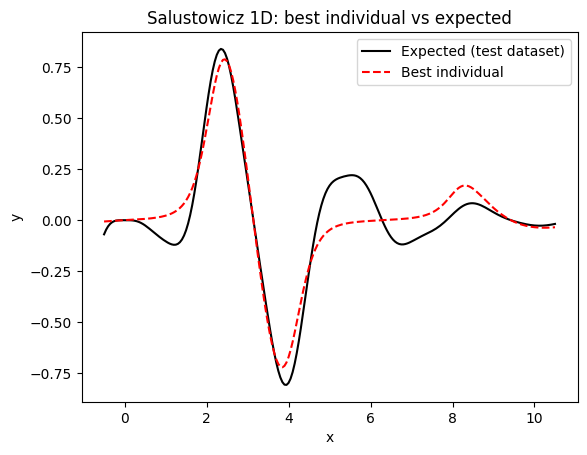

In [62]:
xs = [row[0] for row in test]

plt.plot(xs, [row[1] for row in test], 'k-', label='Expected (test dataset)')
plt.plot(xs, [best_func(x) for x in xs], 'r--', label='Best individual')
plt.xlabel('x')
plt.ylabel('y')
plt.title('Salustowicz 1D: best individual vs expected')
plt.legend()
plt.show()